# Fase 10: Ventana deslizante (entrenar solo con la temporada anterior)
**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025
**Pregunta:** ¿mejora el modelo si, en vez de acumular todo el pasado (ventana expansiva), se entrena **solo con la temporada inmediatamente anterior**?

| Fold | Ventana expansiva (usada en el informe) | Ventana deslizante de 1 temporada (este notebook) |
|---|---|---|
| 1 | entrena 2017/18 → prueba 2018/19 | entrena 2017/18 → prueba 2018/19 (**idéntico**) |
| 2 | entrena 2017/18–2018/19 → prueba 2019/20 | entrena **solo 2018/19** → prueba 2019/20 |
| … | … | … |
| 7 | entrena 2017/18–2023/24 → prueba 2024/25 | entrena **solo 2023/24** → prueba 2024/25 |
| 8 (extra) | entrena 2017/18–2024/25 → prueba 2025/26 | entrena **solo 2024/25** → prueba 2025/26 |

## Hipótesis y protocolo (declarados antes de ver los resultados)
- **Hipótesis a favor de la ventana deslizante:** el fútbol cambia (planteles, tácticas, calidad de las cuotas), por lo que datos antiguos podrían perjudicar.
- **Hipótesis en contra:** una temporada son ~380 partidos; con tan pocos datos los modelos con muchas variables sobreajustan, y el modelo con cuotas necesita pocos datos pero pierde estabilidad.
- **Modelos:** Random Forest (28 variables) y *Solo cuotas* (regresión logística con las 3 probabilidades), con la misma búsqueda de hiperparámetros del notebook 10, dentro de cada ventana (validación interna cronológica, sin tocar la temporada de prueba). Referencia: regla simple del mercado.
- **Criterio de relevancia (fijado de antemano):** la ventana deslizante se considera mejor solo si (i) su accuracy promedio en los 7 folds comparables supera a la expansiva en **más de 1 punto**, (ii) lo hace en **al menos 5 de 7 folds**, y (iii) la prueba exacta de McNemar pareada sobre los 2.626 partidos da p < 0,05. Las tres condiciones son necesarias.
- **Control:** el fold 1 es idéntico en ambos esquemas (mismos datos de entrenamiento y mismo procedimiento), por lo que sus resultados deben coincidir exactamente.

## 1. Datos y ventanas

In [1]:
import os, sys, ast, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, brier_score_loss

sns.set_theme(style='whitegrid', palette='muted'); plt.rcParams['figure.dpi'] = 120
os.makedirs('Imagenes/ventana_deslizante', exist_ok=True)
TARGET = 'target_home_win'
SEL = [c for c in pd.read_csv('Dataset/model_dataset_selected.csv', nrows=1).columns if c not in (TARGET, 'season')]
CUOTAS = ['odds_home_prob', 'odds_draw_prob', 'odds_away_prob']

# 2017/18-2024/25 (datos validados) + 2025/26 (carpeta de la prueba real), mismo archivo con todas las variables
en = pd.read_csv('Dataset/prueba_2025_26/model_dataset_enriched.csv')
orig = pd.read_csv('Dataset/model_dataset_selected.csv')
# los datos 2017-2025 de esta carpeta son los ya validados (se compara por partido: al ordenar por fecha cambia el orden de partidos del mismo día)
o = pd.read_csv('Dataset/model_dataset_enriched.csv')
m = o.merge(en[en.season != '2025-2026'], on=['season', 'home', 'away'], suffixes=('_o', '_e'))
assert len(m) == len(o) == len(orig) and all(np.allclose(m[c + '_o'], m[c + '_e']) for c in SEL + [TARGET])
seasons = sorted(en.season.unique())
print('Temporadas:', seasons); print(en.groupby('season').size().to_dict())

Temporadas: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023', '2023-2024', '2024-2025', '2025-2026']
{'2017-2018': 347, '2018-2019': 371, '2019-2020': 371, '2020-2021': 377, '2021-2022': 377, '2022-2023': 377, '2023-2024': 376, '2024-2025': 377, '2025-2026': 377}


## 2. Entrenamiento por ventana
Dentro de cada ventana de una temporada (~370 partidos) se elige el hiperparámetro con `GridSearchCV` y `TimeSeriesSplit(3)` (validación interna cronológica). La malla es la misma del notebook 10.

In [2]:
GRID_RF = {'n_estimators': [200, 400, 600], 'max_depth': [8, 12, 16, None], 'min_samples_leaf': [2, 4, 8]}
GRID_C = {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}

def ajustar(tr):
    X, y = tr[SEL], tr[TARGET]
    cv = TimeSeriesSplit(n_splits=3)
    rf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced'), GRID_RF, cv=cv, scoring='f1', n_jobs=-1).fit(X, y)
    cu = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), GRID_C, cv=cv, scoring='neg_log_loss', n_jobs=-1).fit(tr[CUOTAS], y)
    return rf, cu

filas, preds = [], []
for k in range(len(seasons) - 1):
    s_tr, s_te = seasons[k], seasons[k + 1]
    te = en[en.season == s_te]
    tr_d = en[en.season == s_tr].sort_values('date')                       # deslizante: solo la temporada anterior
    tr_e = en[en.season.isin(seasons[:k + 1])].sort_values('date')         # expansiva: todo el pasado
    rf_d, cu_d = ajustar(tr_d); rf_e, cu_e = ajustar(tr_e)                  # mismo procedimiento y misma malla en ambas
    d = te[['season', 'home', 'away', TARGET, 'odds_home_prob', 'odds_away_prob']].copy()
    d['fold'] = k + 1; d['train'] = s_tr
    d['p_rf_d'], d['p_cu_d'] = rf_d.predict_proba(te[SEL])[:, 1], cu_d.predict_proba(te[CUOTAS])[:, 1]
    d['p_rf_e'], d['p_cu_e'] = rf_e.predict_proba(te[SEL])[:, 1], cu_e.predict_proba(te[CUOTAS])[:, 1]
    preds.append(d)
    a = lambda c: accuracy_score(te[TARGET], d[c] >= .5)
    print(f'fold {k + 1}: prueba {s_te} | entrena {len(tr_d)} (deslizante) vs {len(tr_e)} (expansiva) | RF {a("p_rf_d"):.3f} vs {a("p_rf_e"):.3f} | cuotas {a("p_cu_d"):.3f} vs {a("p_cu_e"):.3f}')
P = pd.concat(preds, ignore_index=True)

fold 1: prueba 2018-2019 | entrena 347 (deslizante) vs 347 (expansiva) | RF 0.671 vs 0.671 | cuotas 0.712 vs 0.712


fold 2: prueba 2019-2020 | entrena 371 (deslizante) vs 718 (expansiva) | RF 0.695 vs 0.663 | cuotas 0.671 vs 0.663


fold 3: prueba 2020-2021 | entrena 371 (deslizante) vs 1089 (expansiva) | RF 0.668 vs 0.679 | cuotas 0.706 vs 0.700


fold 4: prueba 2021-2022 | entrena 377 (deslizante) vs 1466 (expansiva) | RF 0.698 vs 0.692 | cuotas 0.684 vs 0.687


fold 5: prueba 2022-2023 | entrena 377 (deslizante) vs 1843 (expansiva) | RF 0.647 vs 0.676 | cuotas 0.682 vs 0.676


fold 6: prueba 2023-2024 | entrena 377 (deslizante) vs 2220 (expansiva) | RF 0.681 vs 0.699 | cuotas 0.702 vs 0.694


fold 7: prueba 2024-2025 | entrena 376 (deslizante) vs 2596 (expansiva) | RF 0.660 vs 0.682 | cuotas 0.671 vs 0.668


fold 8: prueba 2025-2026 | entrena 377 (deslizante) vs 2973 (expansiva) | RF 0.634 vs 0.623 | cuotas 0.645 vs 0.629


## 3. Comparación con la ventana expansiva (mismos partidos de prueba)
Para que la comparación sea justa, **ambas ventanas se entrenan aquí con exactamente el mismo procedimiento** (misma malla, misma validación interna); solo cambia cuántos datos de entrenamiento se usan. Como control, se contrasta la expansiva recalculada con la del informe (que usó los hiperparámetros de `04_tuning.ipynb`).

In [3]:
E = pd.read_csv('resultados/predicciones_7folds_y_2025_26.csv')[['season', 'home', 'away', 'p_rf', 'p_cu', 'ok_mer']].rename(columns={'p_rf': 'p_rf_rep', 'p_cu': 'p_cu_rep'})
M = P.merge(E, on=['season', 'home', 'away'], how='left'); assert M.p_rf_rep.notna().all() and len(M) == len(P)
y0 = M[TARGET]
print('Control: la ventana expansiva recalculada aquí vs. la reportada en el informe (hiperparámetros de 04_tuning)')
print(f'  RF accuracy {((M.p_rf_e >= .5) == y0)[M.season != "2025-2026"].mean():.4f} (aquí) vs {((M.p_rf_rep >= .5) == y0)[M.season != "2025-2026"].mean():.4f} (informe) | '
      f'cuotas {((M.p_cu_e >= .5) == y0)[M.season != "2025-2026"].mean():.4f} vs {((M.p_cu_rep >= .5) == y0)[M.season != "2025-2026"].mean():.4f}')
y = M[TARGET]
for t in ('rf_d', 'rf_e', 'cu_d', 'cu_e'): M['ok_' + t] = ((M['p_' + t] >= .5).astype(int) == y).astype(int)
M['ok_mer'] = M['ok_mer'].astype(int)
M.to_csv('resultados/ventana_deslizante_predicciones.csv', index=False)

def resumen(sub):
    f = []
    for nom, col in [('Random Forest — expansiva', 'rf_e'), ('Random Forest — deslizante', 'rf_d'), ('Solo cuotas — expansiva', 'cu_e'), ('Solo cuotas — deslizante', 'cu_d')]:
        p, yy = sub['p_' + col], sub[TARGET]
        f.append({'modelo': nom, 'accuracy': sub['ok_' + col].mean(), 'roc_auc': roc_auc_score(yy, p), 'log_loss': log_loss(yy, p), 'brier': brier_score_loss(yy, p)})
    f.append({'modelo': 'Mercado (regla simple)', 'accuracy': sub.ok_mer.mean(), 'roc_auc': np.nan, 'log_loss': np.nan, 'brier': np.nan})
    return pd.DataFrame(f)

cmp7 = M[M.season != '2025-2026']
R7 = resumen(cmp7); print(f'=== 7 folds comparables ({len(cmp7)} partidos) ==='); print(R7.round(4).to_string(index=False))
R8 = resumen(M[M.season == '2025-2026']); print(f'\n=== Fold extra: 2025/26 ({(M.season == "2025-2026").sum()} partidos) ==='); print(R8.round(4).to_string(index=False))
R7.round(4).to_csv('resultados/ventana_deslizante_resumen.csv', index=False)

Control: la ventana expansiva recalculada aquí vs. la reportada en el informe (hiperparámetros de 04_tuning)
  RF accuracy 0.6805 (aquí) vs 0.6824 (informe) | cuotas 0.6858 vs 0.6858
=== 7 folds comparables (2626 partidos) ===
                    modelo  accuracy  roc_auc  log_loss  brier
 Random Forest — expansiva    0.6805   0.7207    0.6124 0.2119
Random Forest — deslizante    0.6744   0.7182    0.6177 0.2140
   Solo cuotas — expansiva    0.6858   0.7352    0.5979 0.2058
  Solo cuotas — deslizante    0.6896   0.7331    0.5995 0.2064
    Mercado (regla simple)    0.6432      NaN       NaN    NaN

=== Fold extra: 2025/26 (377 partidos) ===
                    modelo  accuracy  roc_auc  log_loss  brier
 Random Forest — expansiva    0.6233   0.6788    0.6337 0.2230
Random Forest — deslizante    0.6340   0.6817    0.6304 0.2212
   Solo cuotas — expansiva    0.6286   0.6971    0.6186 0.2157
  Solo cuotas — deslizante    0.6446   0.6972    0.6188 0.2157
    Mercado (regla simple)    0.6048

In [4]:
por_fold = M.groupby(['fold', 'train', 'season']).agg(partidos=('ok_rf_e', 'size'), RF_expansiva=('ok_rf_e', 'mean'), RF_deslizante=('ok_rf_d', 'mean'),
                                                     Cuotas_expansiva=('ok_cu_e', 'mean'), Cuotas_deslizante=('ok_cu_d', 'mean'), Mercado=('ok_mer', 'mean')).reset_index()
por_fold['dif_RF_pp'] = (por_fold.RF_deslizante - por_fold.RF_expansiva) * 100; por_fold['dif_cuotas_pp'] = (por_fold.Cuotas_deslizante - por_fold.Cuotas_expansiva) * 100
print(por_fold.round(3).to_string(index=False)); por_fold.round(4).to_csv('resultados/ventana_deslizante_por_fold.csv', index=False)
f1 = por_fold[por_fold.fold == 1].iloc[0]; print(f'\nControl fold 1 (debe ser idéntico): RF {f1.RF_expansiva:.4f} vs {f1.RF_deslizante:.4f} | cuotas {f1.Cuotas_expansiva:.4f} vs {f1.Cuotas_deslizante:.4f}')
assert abs(f1.RF_expansiva - f1.RF_deslizante) < 1e-9 and abs(f1.Cuotas_expansiva - f1.Cuotas_deslizante) < 1e-9

 fold     train    season  partidos  RF_expansiva  RF_deslizante  Cuotas_expansiva  Cuotas_deslizante  Mercado  dif_RF_pp  dif_cuotas_pp
    1 2017-2018 2018-2019       371         0.671          0.671             0.712              0.712    0.633      0.000          0.000
    2 2018-2019 2019-2020       371         0.663          0.695             0.663              0.671    0.606      3.235          0.809
    3 2019-2020 2020-2021       377         0.679          0.668             0.700              0.706    0.623     -1.061          0.531
    4 2020-2021 2021-2022       377         0.692          0.698             0.687              0.684    0.671      0.531         -0.265
    5 2021-2022 2022-2023       377         0.676          0.647             0.676              0.682    0.660     -2.918          0.531
    6 2022-2023 2023-2024       376         0.699          0.681             0.694              0.702    0.676     -1.862          0.798
    7 2023-2024 2024-2025       377      

## 4. Prueba pareada (McNemar exacto) y criterio de relevancia

In [5]:
def mcnemar(a, b):
    so_a, so_b = int(((a == 1) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum()); n = so_a + so_b
    return so_a, so_b, (binomtest(so_a, n, .5).pvalue if n else 1.0)

filas = []
for nom, d, e in [('Random Forest', 'ok_rf_d', 'ok_rf_e'), ('Solo cuotas', 'ok_cu_d', 'ok_cu_e')]:
    sub = cmp7; a, b, p = mcnemar(sub[d], sub[e])
    dif = (sub[d].mean() - sub[e].mean()) * 100
    pf = por_fold['dif_RF_pp' if nom == 'Random Forest' else 'dif_cuotas_pp']; mejora = int((pf.iloc[1:7] > 0).sum())
    filas.append({'modelo': nom, 'dif_accuracy_pp (deslizante - expansiva)': round(dif, 2), 'solo_deslizante_acierta': a, 'solo_expansiva_acierta': b, 'p_McNemar': round(p, 4),
                  'folds_donde_mejora (de 6 distintos)': mejora, 'cumple_criterio': bool(dif > 1 and mejora >= 5 and p < 0.05)})
T = pd.DataFrame(filas); print(T.to_string(index=False)); T.to_csv('resultados/ventana_deslizante_mcnemar.csv', index=False)
print('\nNota: el fold 1 es idéntico en ambos esquemas, así que la mejora se cuenta sobre los 6 folds restantes (criterio original: 5 de 7, equivalente a 5 de 6 distintos).')

       modelo  dif_accuracy_pp (deslizante - expansiva)  solo_deslizante_acierta  solo_expansiva_acierta  p_McNemar  folds_donde_mejora (de 6 distintos)  cumple_criterio
Random Forest                                     -0.61                       89                     105     0.2815                                    2            False
  Solo cuotas                                      0.38                       30                      20     0.2026                                    5            False

Nota: el fold 1 es idéntico en ambos esquemas, así que la mejora se cuenta sobre los 6 folds restantes (criterio original: 5 de 7, equivalente a 5 de 6 distintos).


## 5. Figura

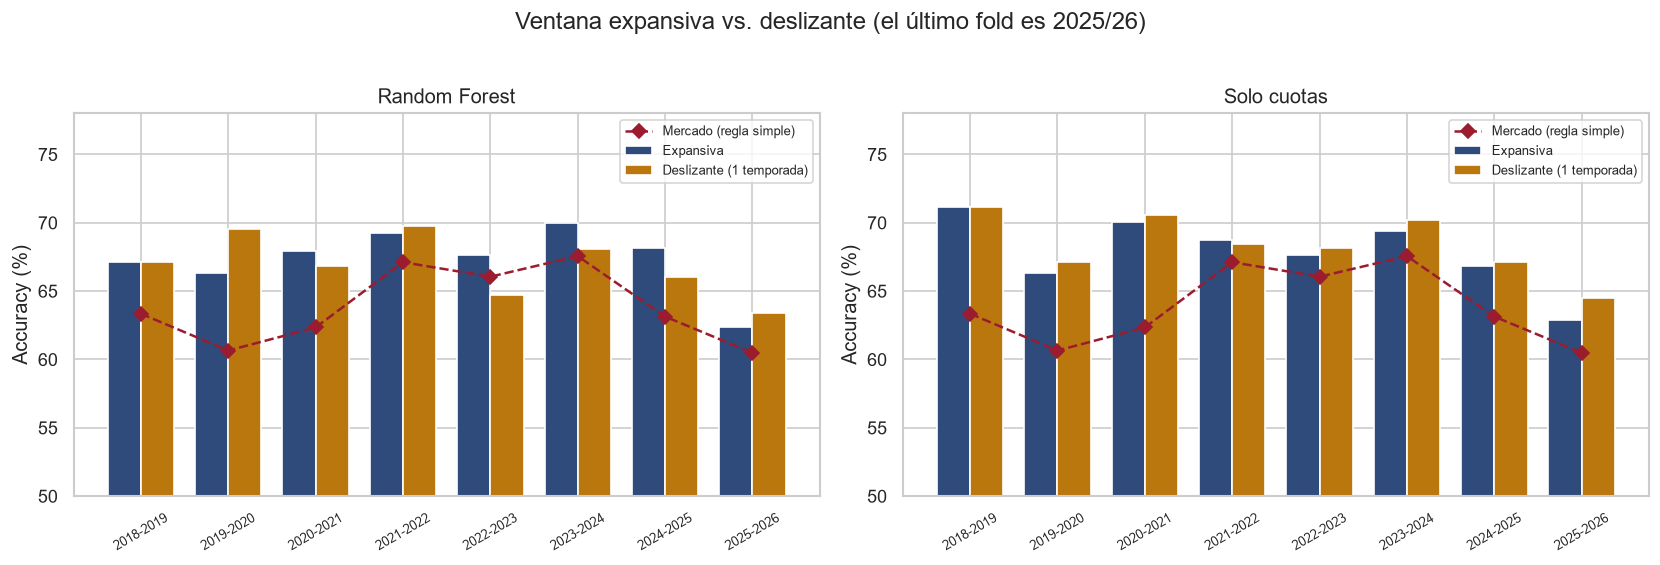

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
x = np.arange(len(por_fold)); w = .38
for a, (e, d, tit) in zip(ax, [('RF_expansiva', 'RF_deslizante', 'Random Forest'), ('Cuotas_expansiva', 'Cuotas_deslizante', 'Solo cuotas')]):
    a.bar(x - w / 2, por_fold[e] * 100, w, label='Expansiva', color='#2F4B7C'); a.bar(x + w / 2, por_fold[d] * 100, w, label='Deslizante (1 temporada)', color='#B9770E')
    a.plot(x, por_fold.Mercado * 100, 'D--', color='#9B1C2E', label='Mercado (regla simple)')
    a.set_xticks(x); a.set_xticklabels(por_fold.season, rotation=30, fontsize=8); a.set_ylim(50, 78); a.set_ylabel('Accuracy (%)'); a.set_title(tit); a.legend(fontsize=8)
plt.suptitle('Ventana expansiva vs. deslizante (el último fold es 2025/26)', y=1.02); plt.tight_layout()
plt.savefig('Imagenes/ventana_deslizante/comparacion_ventanas.png', bbox_inches='tight', dpi=120); plt.show()

## 6. Conclusión

In [7]:
r = T.set_index('modelo')
print('=' * 80); print(' RESUMEN — VENTANA DESLIZANTE vs. EXPANSIVA'); print('=' * 80)
for nom in r.index:
    row = r.loc[nom]
    print(f' {nom}: diferencia {row.iloc[0]:+.2f} pp | mejora en {row.iloc[4]} de 6 folds | McNemar p = {row.iloc[3]:.3f} | criterio cumplido: {row.iloc[5]}')
print(f' Accuracy 2025/26 (fold extra): RF {R8.iloc[1, 1] * 100:.1f}% deslizante vs {R8.iloc[0, 1] * 100:.1f}% expansiva | cuotas {R8.iloc[3, 1] * 100:.1f}% vs {R8.iloc[2, 1] * 100:.1f}%')
print('=' * 80)

 RESUMEN — VENTANA DESLIZANTE vs. EXPANSIVA
 Random Forest: diferencia -0.61 pp | mejora en 2 de 6 folds | McNemar p = 0.281 | criterio cumplido: False
 Solo cuotas: diferencia +0.38 pp | mejora en 5 de 6 folds | McNemar p = 0.203 | criterio cumplido: False
 Accuracy 2025/26 (fold extra): RF 63.4% deslizante vs 62.3% expansiva | cuotas 64.5% vs 62.9%
